# Week 3 · Part C — Prove the palette, don't claim it

Roughly 1 man in 12 and 1 woman in 200 has some form of colour-vision deficiency (CVD). Here every claim is a number from
`vizlib.simulate_cvd()` (Machado et al. 2009, linear RGB) and `vizlib.worst_pair()` (ΔE in OKLab).
Thresholds from `vizlib.delta_e`: ≥ 15 clear · ≥ 8 target after CVD · 6–8 only with a second channel (shape, label, texture) · < 6 same colour.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
from vizlib import PALETTE, simulate_cvd, worst_pair, verdict, delta_e, style_defaults

style_defaults(dpi=100)
FIG = Path("figs"); FIG.mkdir(exist_ok=True)
KINDS = ["normal", "deutan", "protan", "tritan"]

MY_LABEL = "matplotlib tab10, first four (a palette I did NOT assume was safe)"
MY_PALETTE = ["#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"]       # blue, orange, green, red
COURSE_LABEL = "course palette: 3 Okabe-Ito slots + 4th slot"
COURSE = PALETTE["series"] + [PALETTE["series_4th"]]
print(MY_PALETTE); print(COURSE)

['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728']
['#0072B2', '#D55E00', '#009E73', '#CC79A7']


## 1 · Before / after swatches for my own palette (3 marks)
I picked the first four colours of matplotlib's default `tab10` — the palette most notebooks ship with — blue, orange, **green and red**. Red + green is the classic trap, so I want the number, not the guess.

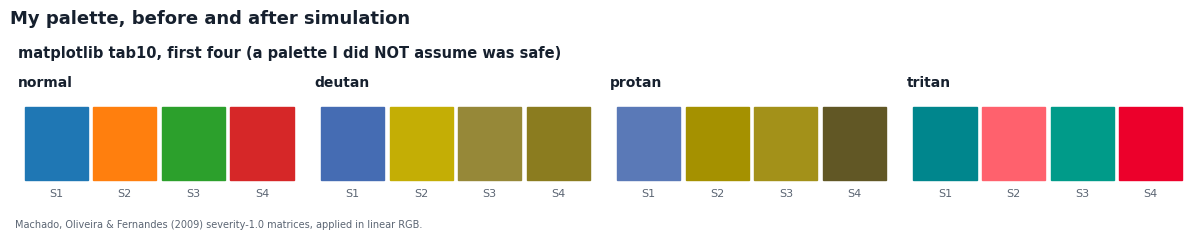

deutan  ['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728'] -> ['#456CB3', '#C4AE05', '#968838', '#8B7C1F']
protan  ['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728'] -> ['#5A79B7', '#A59100', '#A39119', '#615725']
tritan  ['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728'] -> ['#00868D', '#FF616D', '#009B89', '#EC002B']


In [2]:
def swatches(palettes, path, title):
    fig, axes = plt.subplots(len(palettes), len(KINDS), figsize=(3.0 * len(KINDS), 2.2 * len(palettes)))
    axes = np.atleast_2d(axes)
    for row, (pal, label) in enumerate(palettes):
        for col, kind in enumerate(KINDS):
            ax = axes[row, col]
            shown = pal if kind == "normal" else simulate_cvd(pal, kind)
            for i, hexc in enumerate(shown):
                ax.add_patch(plt.Rectangle((i, 0), 0.92, 1, color=hexc))
                ax.text(i + 0.46, -0.22, f"S{i+1}", ha="center", fontsize=8, color=PALETTE["ink_soft"])
            ax.set_xlim(-0.1, len(pal)); ax.set_ylim(-0.4, 1.1); ax.axis("off"); ax.set_title(kind, fontsize=10)
    fig.suptitle(title, x=0.006, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.9])
    for row, (pal, label) in enumerate(palettes):          # row labels added AFTER tight_layout so a long label cannot squeeze the axes
        pos = axes[row, 0].get_position()
        fig.text(pos.x0, pos.y1 + 0.42 / fig.get_figheight(), label, fontsize=10.5, fontweight="bold", color=PALETTE["ink"])
    fig.text(0.01, -0.01, "Machado, Oliveira & Fernandes (2009) severity-1.0 matrices, applied in linear RGB.", fontsize=7, color=PALETTE["ink_soft"])
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

swatches([(MY_PALETTE, MY_LABEL)], FIG / "C_my_palette.png", "My palette, before and after simulation")
for kind in ["deutan", "protan", "tritan"]:
    print(kind.ljust(7), MY_PALETTE, "->", simulate_cvd(MY_PALETTE, kind))

## 2 · The same for `vizlib.PALETTE["series"]` + the 4th slot (2 marks)

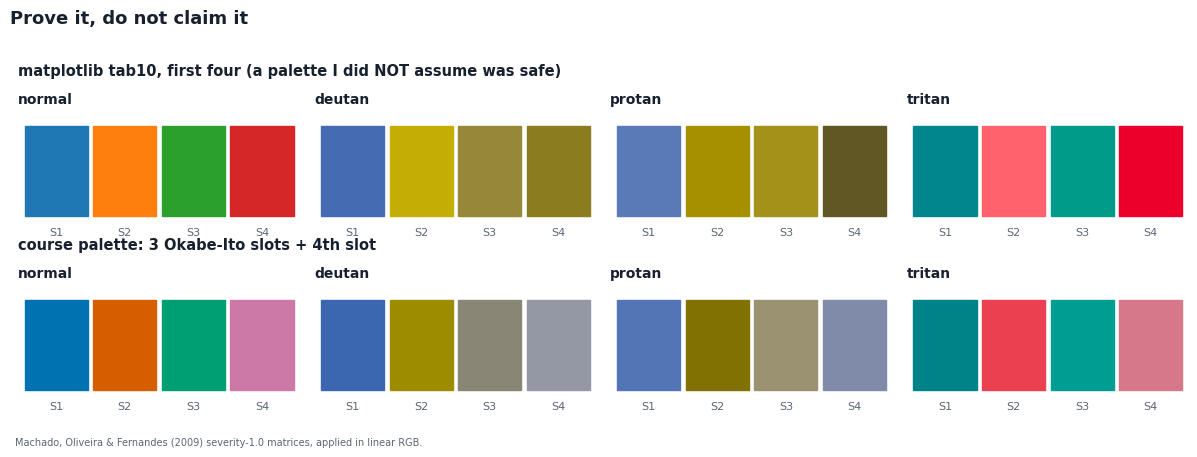

deutan  ['#0072B2', '#D55E00', '#009E73', '#CC79A7'] -> ['#3B67B1', '#9E8C00', '#8A8676', '#9498A5']
protan  ['#0072B2', '#D55E00', '#009E73', '#CC79A7'] -> ['#5375B5', '#817100', '#9A9271', '#808BA9']
tritan  ['#0072B2', '#D55E00', '#009E73', '#CC79A7'] -> ['#008289', '#EB4050', '#009E92', '#D6788A']


In [3]:
swatches([(MY_PALETTE, MY_LABEL), (COURSE, COURSE_LABEL)], FIG / "C_palette_check.png", "Prove it, do not claim it")
for kind in ["deutan", "protan", "tritan"]:
    print(kind.ljust(7), COURSE, "->", simulate_cvd(COURSE, kind))

## 3 · The worst pair in each palette (2 marks)
`worst_pair()` compares **every** pair (not just neighbours), which is the right test for a scatter plot or map where any two series can touch.

In [4]:
rows = []
for label, pal in [("my palette (tab10 first 4)", MY_PALETTE), ("course, 3 slots", PALETTE["series"]), ("course + 4th slot", COURSE)]:
    for kind in KINDS:
        i, j, a, b, d = worst_pair(pal, None if kind == "normal" else kind)
        rows.append({"palette": label, "vision": kind, "worst pair": f"S{i}/S{j}", "colours": f"{a} / {b}", "dE": round(d, 1), "verdict": verdict(d)})
report = pd.DataFrame(rows)
report

,palette,vision,worst pair,colours,dE,verdict
0,my palette (tab10 first 4),normal,S2/S4,#FF7F0E / #D62728,18.6,clear
1,my palette (tab10 first 4),deutan,S3/S4,#2CA02C / #D62728,4.1,FAILS — same colour
2,my palette (tab10 first 4),protan,S2/S3,#FF7F0E / #2CA02C,0.7,FAILS — same colour
3,my palette (tab10 first 4),tritan,S1/S3,#1F77B4 / #2CA02C,6.7,needs a second channel
4,"course, 3 slots",normal,S1/S3,#0072B2 / #009E73,18.7,clear
5,"course, 3 slots",deutan,S2/S3,#D55E00 / #009E73,11.0,ok
6,"course, 3 slots",protan,S2/S3,#D55E00 / #009E73,13.0,ok
7,"course, 3 slots",tritan,S1/S3,#0072B2 / #009E73,8.4,ok
8,course + 4th slot,normal,S2/S4,#D55E00 / #CC79A7,16.4,clear
9,course + 4th slot,deutan,S3/S4,#009E73 / #CC79A7,7.5,needs a second channel


In [5]:
pd.set_option("display.width", 200)
piv = report.pivot(index="vision", columns="palette", values="dE").loc[KINDS]
print("worst-pair dE (higher is safer):"); print(piv)
print()
print(report[report.vision.isin(["deutan", "protan"])].sort_values("dE").head(6).to_string(index=False))

worst-pair dE (higher is safer):
palette  course + 4th slot  course, 3 slots  my palette (tab10 first 4)
vision                                                                 
normal                16.4             18.7                        18.6
deutan                 7.5             11.0                         4.1
protan                 9.5             13.0                         0.7
tritan                 8.4              8.4                         6.7

                   palette vision worst pair           colours   dE                verdict
my palette (tab10 first 4) protan      S2/S3 #FF7F0E / #2CA02C  0.7    FAILS — same colour
my palette (tab10 first 4) deutan      S3/S4 #2CA02C / #D62728  4.1    FAILS — same colour
         course + 4th slot deutan      S3/S4 #009E73 / #CC79A7  7.5 needs a second channel
         course + 4th slot protan      S1/S4 #0072B2 / #CC79A7  9.5                     ok
           course, 3 slots deutan      S2/S3 #D55E00 / #009E73 11.0            

**Reading the numbers** (all values are printed above; ΔE is OKLab ×100):

* **My `tab10` palette fails.** Normal vision is fine (worst ΔE 18.6), but under **deuteranopia the green (S3) and red (S4) collapse to ΔE 4.1** and under **protanopia the orange (S2) and green (S3) collapse to ΔE 0.7** — effectively the same colour (both "FAILS — same colour", < 6). Under tritanopia the worst pair is blue/green at ΔE 6.7 (needs a second channel). It looks fine to me and would be unreadable to roughly 1 man in 12.
* **The course palette is safe with three slots.** Its worst pair under deuteranopia is **S2/S3 (vermilion `#D55E00` / green `#009E73`), ΔE = 11.0** (13.0 under protanopia, 8.4 for tritanopia on S1/S3, 18.7 under normal vision) — every value is ≥ 8, so it passes.
* **The course palette *has* a weak pair once the 4th slot is added:** `#CC79A7` (S4) pairs with S3 (`#009E73`) under deuteranopia at **ΔE = 7.5 — in the 6–8 "needs a second channel" band**.
  **What that means for how I may use it:** slot 4 is legal **only** when the chart also carries direct labels, a different marker shape, or a table view; it must never be the only thing telling two series apart. It also falls below 3:1 contrast on white, so it is not for thin lines or small text.

## 4 · The rule I will follow when a chart needs more than three categories (2 marks)

> **Three colours is the ceiling for colour as an identifier. Beyond three, I stop adding hues and add a second encoding channel instead:**
> direct labels on the marks (no legend lookup), different marker shapes (`MARKERS = o, s, ^, D`), line styles/textures, small multiples (one panel per category, all in one neutral colour), or grey-for-context with a single highlighted series.
> If a 4th hue (`#CC79A7`) is used it **must** be accompanied by direct labels or a table, and I re-run `simulate_cvd()` / `worst_pair()` on the exported figure.

The reason is in the table above: the fourth slot costs 3.5 ΔE points of CVD margin (11.0 → 7.5), so the answer to "I need more categories" is not a bigger palette — a bigger palette only moves more pairs into the 6–8 band — but more *channels*, which cost nothing in distinguishability.

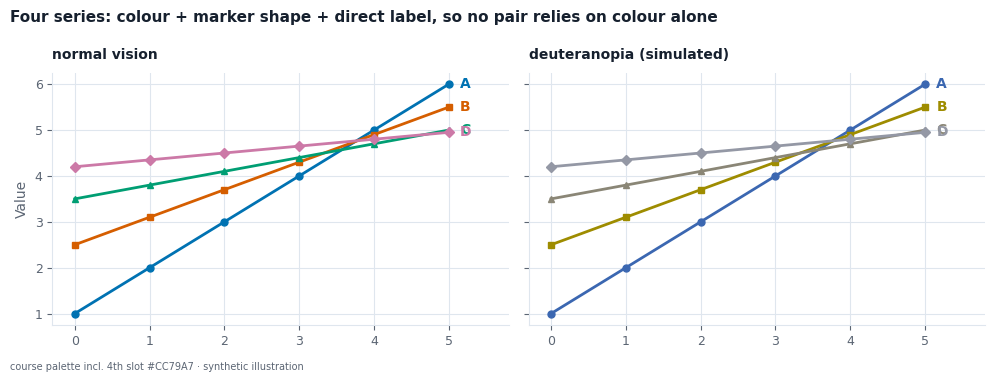

In [6]:
# demonstration: the 4th slot + a second channel (labels + markers) survives deuteranopia
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
x = np.arange(6)
series = {"A": x * 1.0 + 1, "B": x * 0.6 + 2.5, "C": x * 0.3 + 3.5, "D": x * 0.15 + 4.2}
for ax, kind in zip(axes, ["normal", "deutan"]):
    cols = COURSE if kind == "normal" else simulate_cvd(COURSE, kind)
    for (name, y), col, mk in zip(series.items(), cols, ["o", "s", "^", "D"]):
        ax.plot(x, y, color=col, marker=mk, lw=2)
        ax.text(x[-1] + 0.15, y[-1], name, color=col, va="center", fontweight="bold")     # direct label = second channel
    ax.set_xlim(-0.3, 5.8); ax.set_title("normal vision" if kind == "normal" else "deuteranopia (simulated)", fontsize=10)
axes[0].set_ylabel("Value")
fig.suptitle("Four series: colour + marker shape + direct label, so no pair relies on colour alone", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.text(0.01, -0.02, "course palette incl. 4th slot #CC79A7 · synthetic illustration", fontsize=7, color=PALETTE["ink_soft"])
fig.savefig(FIG / "C_fourth_slot_with_second_channel.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()